In [2]:
print("Welcome to Sales Performance Analytics!")

Welcome to Sales Performance Analytics!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All Python libraries imported successfully!")

All Python libraries imported successfully!


In [4]:
import pandas as pd
from pathlib import Path

# Go back one folder, then open the Excel folder
file_path = Path("../excel/sales_analysis.xlsx")

# Load the Orders worksheet
df = pd.read_excel(file_path, sheet_name="Orders")

# Display the first five rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1.0,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2.0,0.2,5.5512
1,2.0,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2.0,0.8,-5.4870
2,3.0,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3.0,0.2,4.2717
3,4.0,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3.0,0.2,-64.7748
4,5.0,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3.0,0.2,4.8840


In [5]:
# Check the number of rows and columns
df.shape

(10211, 21)

In [6]:
# Display column names, data types and missing-value counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10211 entries, 0 to 10210
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  float64       
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10193 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10195 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [7]:
# Check for missing values in each column
df.isnull().sum()

Row ID            17
Order ID          17
Order Date        17
Ship Date         17
Ship Mode         17
Customer ID       17
Customer Name     17
Segment           17
Country/Region    17
City              18
State/Province    17
Postal Code       17
Region            16
Product ID        17
Category          17
Sub-Category      17
Product Name      17
Sales             17
Quantity          17
Discount          17
Profit            17
dtype: int64

In [8]:
# Display rows containing at least one missing value
missing_rows = df[df.isnull().any(axis=1)]

missing_rows

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10182,10183.0,US-2026-118885,2026-12-29,2027-01-02,Standard Class,JG-15160,James Galang,Consumer,United States,NaN,...,90049,West,TEC-PH-10002563,Technology,Phones,Adtran 1202752G1,302.376,3.0,0.2,22.6782
10194,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10195,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10196,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10197,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10198,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10199,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10200,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10201,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10202,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Count rows where every column is missing
blank_rows = df.isnull().all(axis=1)

print("Completely blank rows:", blank_rows.sum())

Completely blank rows: 16


In [10]:
# Create a cleaned copy of the dataset
df_clean = df.dropna(how="all").copy()

# Compare the original and cleaned datasets
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

Original dataset: (10211, 21)
Cleaned dataset: (10195, 21)
Rows removed: 16


In [11]:
# Check missing values after removing blank rows
df_clean.isnull().sum()

Row ID            1
Order ID          1
Order Date        1
Ship Date         1
Ship Mode         1
Customer ID       1
Customer Name     1
Segment           1
Country/Region    1
City              2
State/Province    1
Postal Code       1
Region            0
Product ID        1
Category          1
Sub-Category      1
Product Name      1
Sales             1
Quantity          1
Discount          1
Profit            1
dtype: int64

In [12]:
# Find rows that still contain missing values
incomplete_rows = df_clean[df_clean.isnull().any(axis=1)]

# Display the incomplete records
incomplete_rows

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10182,10183.0,US-2026-118885,2026-12-29,2027-01-02,Standard Class,JG-15160,James Galang,Consumer,United States,NaN,...,90049,West,TEC-PH-10002563,Technology,Phones,Adtran 1202752G1,302.376,3.0,0.2,22.6782
10210,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Display only the missing fields for each incomplete row
for index, row in incomplete_rows.iterrows():
    print(f"\nRow index: {index}")
    print("Missing columns:")
    print(row[row.isna()].index.tolist())


Row index: 10182
Missing columns:
['City']

Row index: 10210
Missing columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [15]:
# Inspect the remaining information in row 10210
df_clean.loc[10210].dropna()

Region    T
Name: 10210, dtype: object

In [16]:
# Remove the invalid record
df_clean = df_clean.drop(index=10210)

# Check the remaining missing values
print("Dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

Dataset shape: (10194, 21)

Remaining missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              1
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [17]:
# Find the sales record with a missing City
missing_city = df_clean[df_clean["City"].isnull()]

# Display relevant information
missing_city[
    ["Order ID", "Customer Name", "Country/Region",
     "State/Province", "Postal Code", "Region",
     "Sales", "Profit"]
]

,Order ID,Customer Name,Country/Region,State/Province,Postal Code,Region,Sales,Profit
10182,US-2026-118885,James Galang,United States,California,90049,West,302.376,22.6782


In [18]:
# Display location details for the missing City
missing_city[
    ["Country/Region", "State/Province", "Postal Code", "Region"]
]

,Country/Region,State/Province,Postal Code,Region
10182,United States,California,90049,West


In [19]:
# Find other records with the same postal code
matching_cities = df_clean[
    (df_clean["Postal Code"].astype(str).str.replace(r"\.0$", "", regex=True) == "90049") &
    (df_clean["State/Province"] == "California") &
    (df_clean["Country/Region"] == "United States")
]

# Display the cities associated with this postal code
matching_cities["City"].value_counts(dropna=False)

City
Los Angeles    150
NaN              1
Name: count, dtype: int64

In [20]:
# Count cities associated with postal code 90049
matching_cities["City"].value_counts(dropna=False)

City
Los Angeles    150
NaN              1
Name: count, dtype: int64

In [21]:
# Fill the missing City value
df_clean.loc[10182, "City"] = "Los Angeles"

# Verify the updated record
print("Updated City:", df_clean.loc[10182, "City"])

# Check remaining missing values
print("\nTotal missing values:", df_clean.isnull().sum().sum())

Updated City: Los Angeles

Total missing values: 0


In [22]:
# Check for completely duplicate rows
duplicate_rows = df_clean.duplicated().sum()

# Display the results
print("Total records:", len(df_clean))
print("Duplicate rows:", duplicate_rows)

Total records: 10194
Duplicate rows: 0


In [23]:
# Check the cleaned dataset
print("Dataset shape:", df_clean.shape)

print("\nColumn data types:")
print(df_clean.dtypes)

print("\nTotal missing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

Dataset shape: (10194, 21)

Column data types:
Row ID                   float64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code               object
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                 float64
Discount                 float64
Profit                   float64
dtype: object

Total missing values:
0

Duplicate rows:
0


In [24]:
# Check whether Row ID and Quantity contain whole numbers
for column in ["Row ID", "Quantity"]:
    decimal_values = (
        df_clean[column] % 1 != 0
    ).sum()

    print(f"{column}: {decimal_values} decimal values")

Row ID: 0 decimal values
Quantity: 0 decimal values


In [25]:
# Convert whole-number columns to integers
df_clean["Row ID"] = df_clean["Row ID"].astype("int64")
df_clean["Quantity"] = df_clean["Quantity"].astype("int64")

# Verify the updated data types
print(df_clean[["Row ID", "Quantity"]].dtypes)

Row ID      int64
Quantity    int64
dtype: object


In [26]:
# Task 16: Descriptive Statistics

# Select numerical columns for analysis
numerical_columns = [
    "Sales",
    "Profit",
    "Quantity",
    "Discount"
]

# Generate descriptive statistics
descriptive_stats = df_clean[numerical_columns].describe()

# Display the results
descriptive_stats.round(2)

,Sales,Profit,Quantity,Discount
count,10194.00,10194.00,10194.00,10194.00
mean,228.23,28.67,3.79,0.16
std,619.91,232.47,2.23,0.21
min,0.44,-6599.98,1.00,0.00
25%,17.22,1.76,2.00,0.00
50%,53.91,8.69,3.00,0.20
75%,209.50,29.30,5.00,0.20
max,22638.48,8399.98,14.00,0.80


In [28]:
#Calculate Business KPIs

# Calculate total revenue
total_revenue = df_clean["Sales"].sum()

# Calculate total profit
total_profit = df_clean["Profit"].sum()

# Calculate profit margin
profit_margin = (total_profit / total_revenue) * 100

# Count unique orders
total_orders = df_clean["Order ID"].nunique()

# Calculate average order value
average_order_value = total_revenue / total_orders

# Display KPI results
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")


Total Revenue: $2,326,534.35
Total Profit: $292,296.81
Profit Margin: 12.56%
Total Orders: 5,111
Average Order Value: $455.20


In [29]:
# Sales Performance by Category

category_performance = (
    df_clean.groupby("Category")
    .agg(
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate profit margin for each category
category_performance["Profit_Margin"] = (
    category_performance["Total_Profit"]
    / category_performance["Total_Revenue"]
) * 100

# Display results
category_performance.round(2)

,Category,Total_Revenue,Total_Profit,Total_Quantity,Profit_Margin
0,Furniture,754747.76,19730.00,8369,2.61
1,Office Supplies,731893.31,126023.44,23268,17.22
2,Technology,839893.28,146543.38,7017,17.45


In [30]:

#  Profitability by Subcategory

subcategory_performance = (
    df_clean.groupby(["Category", "Sub-Category"])
    .agg(
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

# Calculate profit margin
subcategory_performance["Profit_Margin"] = (
    subcategory_performance["Total_Profit"]
    / subcategory_performance["Total_Revenue"]
) * 100

# Sort from lowest to highest profit
subcategory_performance = subcategory_performance.sort_values(
    by="Total_Profit",
    ascending=True
)

# Display results
subcategory_performance.round(2)


,Category,Sub-Category,Total_Revenue,Total_Profit,Profit_Margin
3,Furniture,Tables,208020.18,-17753.21,-8.53
0,Furniture,Bookcases,115361.20,-3632.07,-3.15
12,Office Supplies,Supplies,46725.50,-1171.39,-2.51
8,Office Supplies,Fasteners,8532.24,2428.64,28.46
15,Technology,Machines,189925.03,3461.98,1.82
9,Office Supplies,Labels,12695.04,5572.78,43.90
5,Office Supplies,Art,27659.01,6653.20,24.05
7,Office Supplies,Envelopes,16528.36,6988.02,42.28
2,Furniture,Furnishings,95598.13,13891.74,14.53
4,Office Supplies,Appliances,108213.18,18329.48,16.94


In [31]:

#Regional Sales Performance

regional_performance = (
    df_clean.groupby("Region")
    .agg(
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

# Calculate regional profit margins
regional_performance["Profit_Margin"] = (
    regional_performance["Total_Profit"]
    / regional_performance["Total_Revenue"]
) * 100

# Sort regions by revenue
regional_performance = regional_performance.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Display results
regional_performance.round(2)


,Region,Total_Revenue,Total_Profit,Total_Orders,Profit_Margin
3,West,739813.61,110798.82,1635,14.98
1,East,691828.17,94883.26,1475,13.71
0,Central,503170.67,39865.31,1179,7.92
2,South,391721.90,46749.43,822,11.93


In [32]:

#Monthly Sales Trends

# Create a monthly period column
df_clean["Year_Month"] = (
    df_clean["Order Date"].dt.to_period("M")
)

# Calculate monthly revenue and profit
monthly_performance = (
    df_clean.groupby("Year_Month")
    .agg(
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

# Display monthly results
monthly_performance.round(2)


C:\Users\HighveldVR2\AppData\Local\Temp\ipykernel_22976\2258318517.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_performance.round(2)


,Year_Month,Total_Revenue,Total_Profit
0,2023-01,14518.06,2539.39
1,2023-02,4519.89,862.31
2,2023-03,56933.91,693.45
3,2023-04,28295.34,3488.84
4,2023-05,26319.77,3196.39
5,2023-06,34669.48,4999.76
6,2023-07,33946.39,-841.48
7,2023-08,28918.34,5765.22
8,2023-09,82670.43,8593.63
9,2023-10,32413.34,3469.17


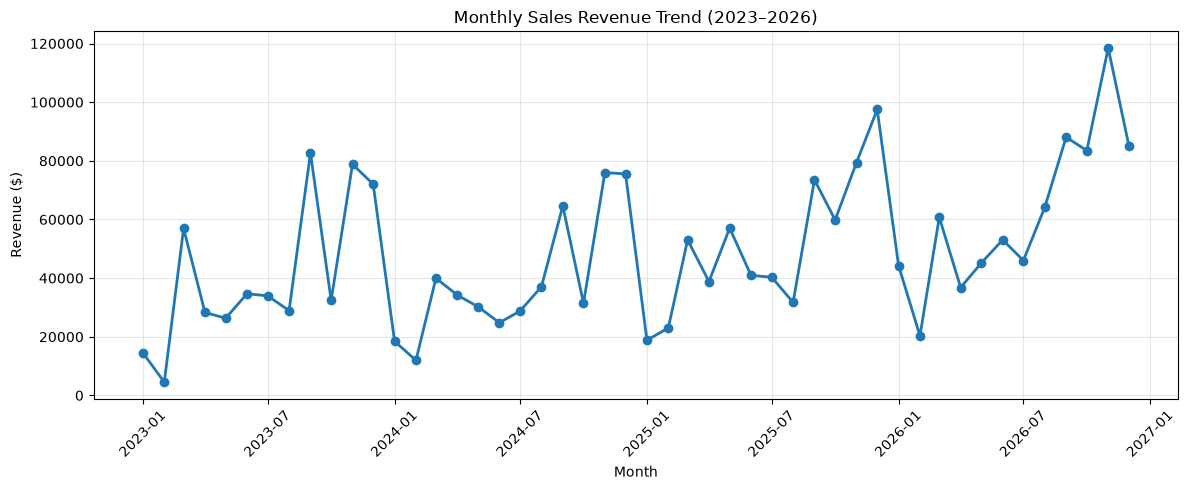

In [33]:

#Monthly Revenue Trend Visualisation

import matplotlib.pyplot as plt

# Convert monthly periods to timestamps for plotting
months = monthly_performance["Year_Month"].dt.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(
    months,
    monthly_performance["Total_Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Revenue Trend (2023–2026)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


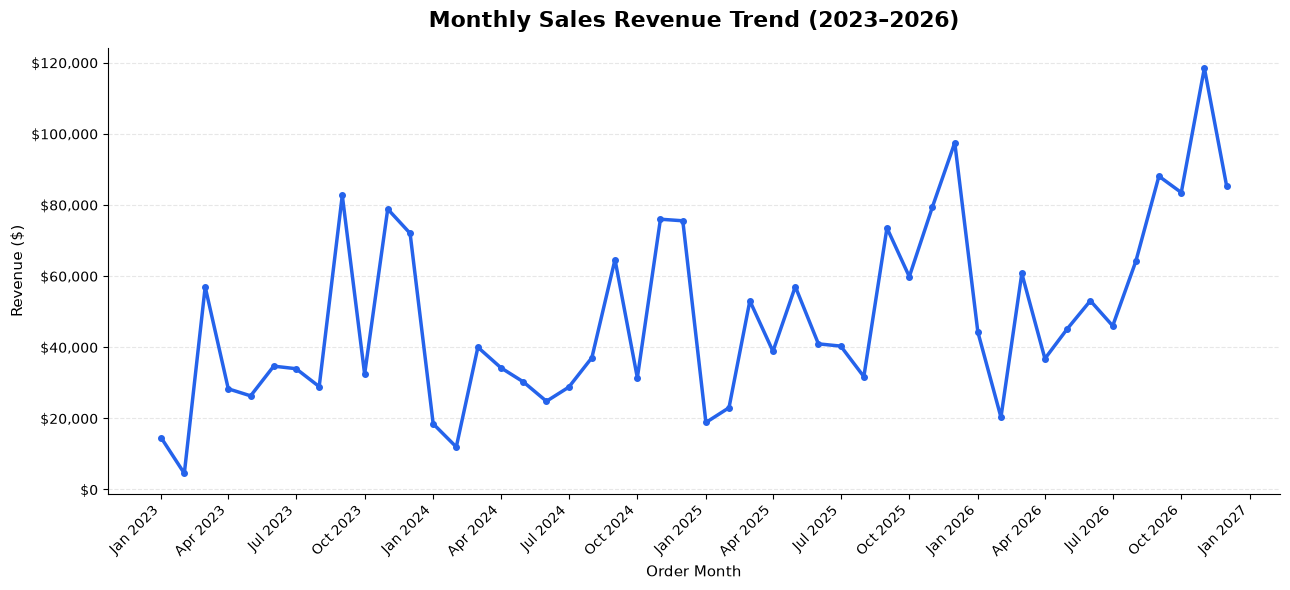

In [34]:

#Professional Monthly Revenue Chart

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Convert monthly periods to dates
months = monthly_performance["Year_Month"].dt.to_timestamp()

# Create chart
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    months,
    monthly_performance["Total_Revenue"],
    color="#2563EB",
    linewidth=2.5,
    marker="o",
    markersize=4
)

# Chart title and labels
ax.set_title(
    "Monthly Sales Revenue Trend (2023–2026)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Order Month", fontsize=11)
ax.set_ylabel("Revenue ($)", fontsize=11)

# Show year and month labels every 3 months
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Format revenue as currency
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Improve readability
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


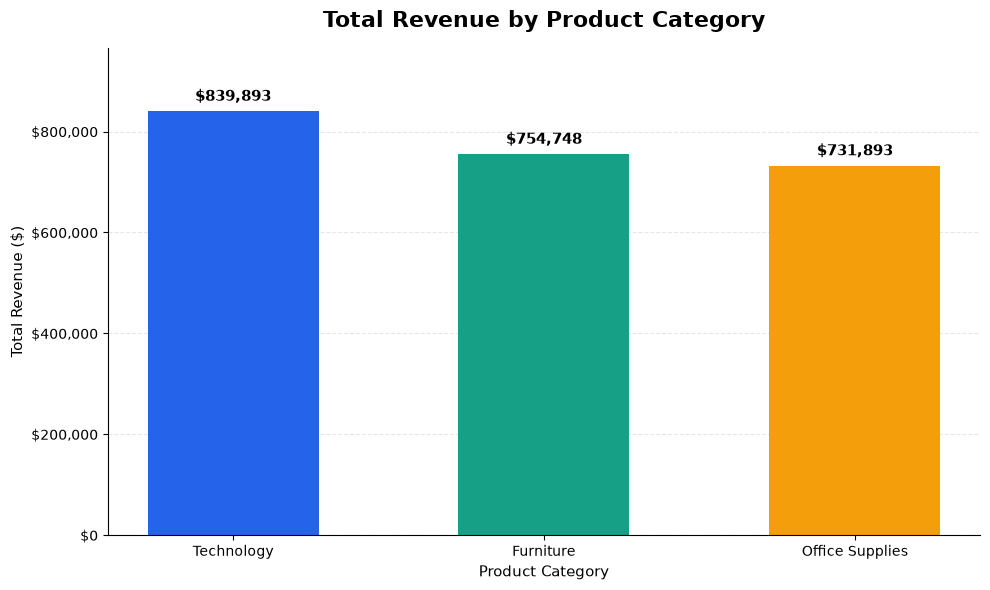

In [35]:

#Revenue by Product Category

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort categories by revenue
category_chart = category_performance.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Create chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    category_chart["Category"],
    category_chart["Total_Revenue"],
    color=["#2563EB", "#16A085", "#F59E0B"],
    width=0.55
)

# Add revenue labels above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"${height:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Chart title and labels
ax.set_title(
    "Total Revenue by Product Category",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Product Category", fontsize=11)
ax.set_ylabel("Total Revenue ($)", fontsize=11)

# Format revenue axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Improve appearance
ax.set_ylim(0, category_chart["Total_Revenue"].max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


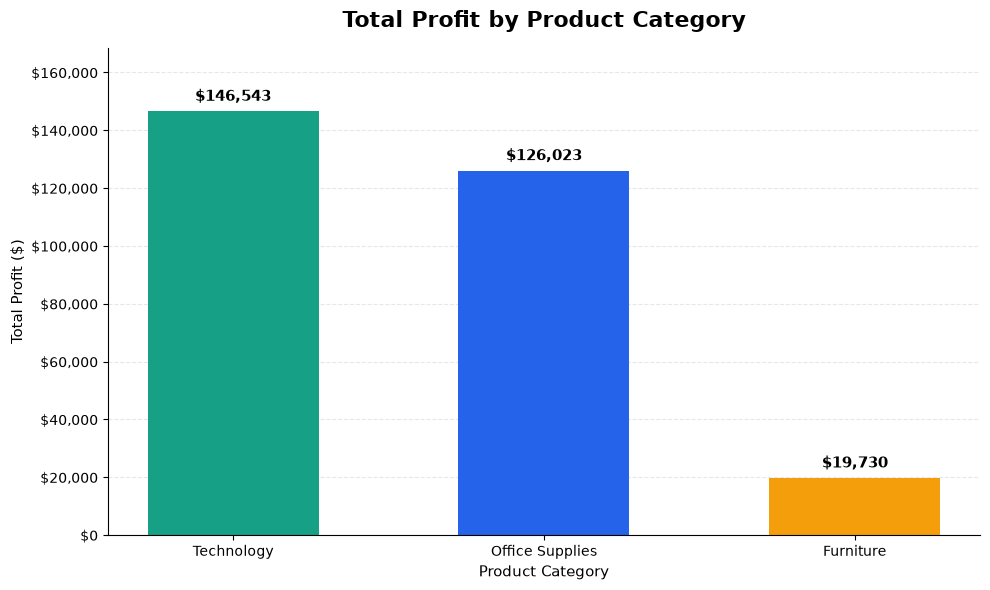

In [36]:

#Profit by Product Category

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort categories by total profit
profit_chart = category_performance.sort_values(
    by="Total_Profit",
    ascending=False
)

# Assign colours based on profitability
colors = ["#16A085", "#2563EB", "#F59E0B"]

# Create chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    profit_chart["Category"],
    profit_chart["Total_Profit"],
    color=colors,
    width=0.55
)

# Add profit labels above each bar
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"${height:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Add title and labels
ax.set_title(
    "Total Profit by Product Category",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Product Category", fontsize=11)
ax.set_ylabel("Total Profit ($)", fontsize=11)

# Format profit axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Improve chart appearance
ax.set_ylim(0, profit_chart["Total_Profit"].max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


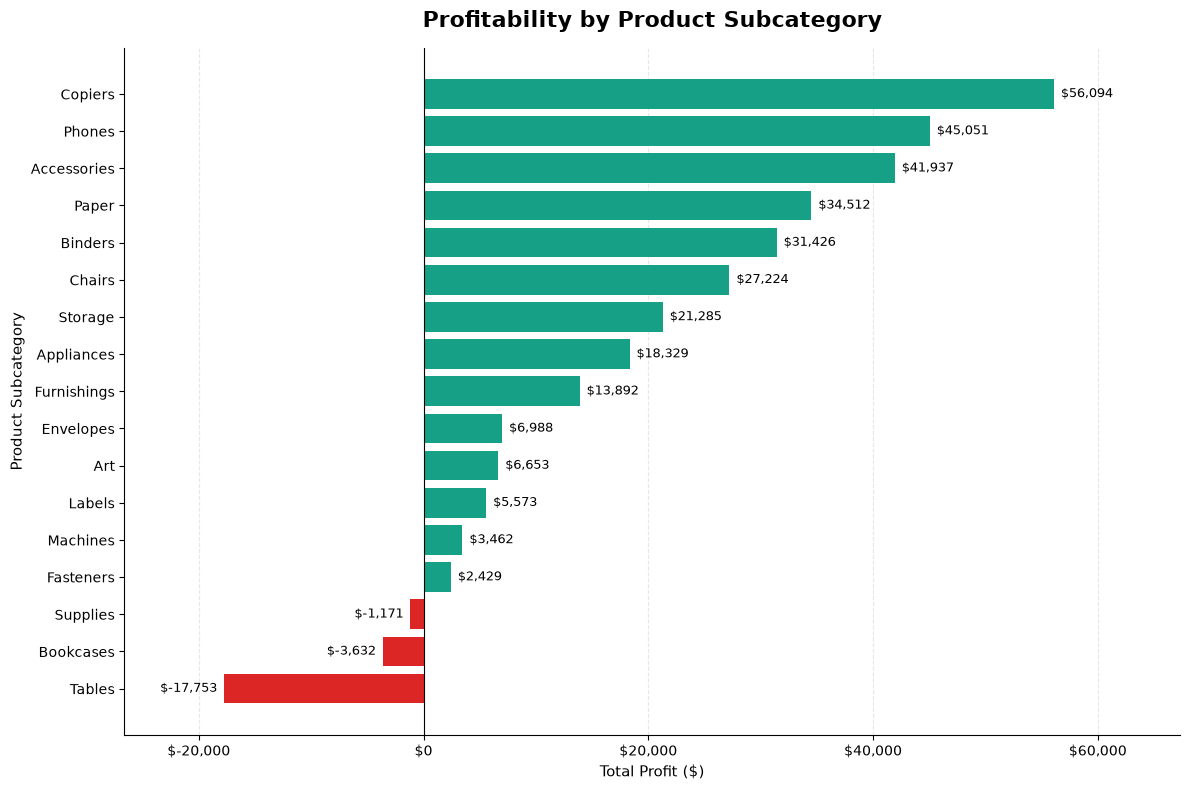

In [37]:

#Profitability by Subcategory

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort subcategories from lowest to highest profit
subcategory_chart = subcategory_performance.sort_values(
    by="Total_Profit",
    ascending=True
)

# Use red for losses and green for profits
colors = [
    "#DC2626" if profit < 0 else "#16A085"
    for profit in subcategory_chart["Total_Profit"]
]

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    subcategory_chart["Sub-Category"],
    subcategory_chart["Total_Profit"],
    color=colors
)

# Add profit labels
for bar in bars:
    width = bar.get_width()

    ax.annotate(
        f"${width:,.0f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if width >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if width >= 0 else "right",
        va="center",
        fontsize=9
    )

# Chart title and labels
ax.set_title(
    "Profitability by Product Subcategory",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Total Profit ($)", fontsize=11)
ax.set_ylabel("Product Subcategory", fontsize=11)

# Format profit axis
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Add zero reference line
ax.axvline(0, color="black", linewidth=0.8)

# Leave room for labels
ax.set_xlim(
    subcategory_chart["Total_Profit"].min() * 1.5,
    subcategory_chart["Total_Profit"].max() * 1.2
)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


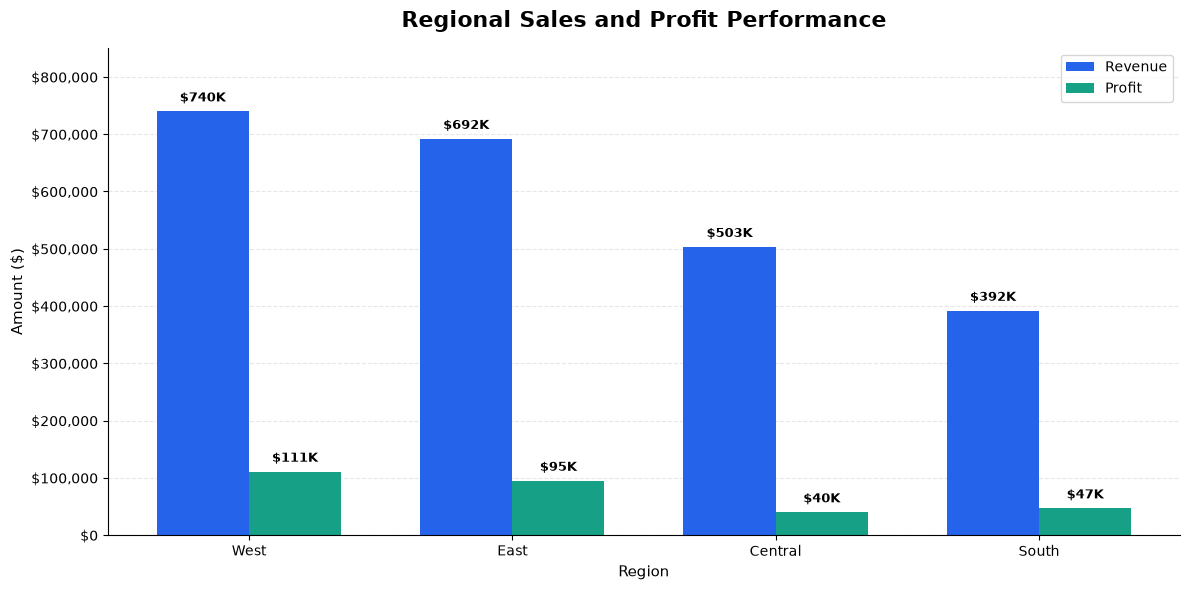

In [38]:

#Regional Sales Performance Chart

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# Sort regions by revenue
regional_chart = regional_performance.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Set bar positions
x = np.arange(len(regional_chart["Region"]))
width = 0.35

# Create chart
fig, ax = plt.subplots(figsize=(12, 6))

# Revenue bars
revenue_bars = ax.bar(
    x - width / 2,
    regional_chart["Total_Revenue"],
    width,
    label="Revenue",
    color="#2563EB"
)

# Profit bars
profit_bars = ax.bar(
    x + width / 2,
    regional_chart["Total_Profit"],
    width,
    label="Profit",
    color="#16A085"
)

# Add labels above bars
for bars in [revenue_bars, profit_bars]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"${height / 1000:,.0f}K",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

# Chart title and labels
ax.set_title(
    "Regional Sales and Profit Performance",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Region", fontsize=11)
ax.set_ylabel("Amount ($)", fontsize=11)

# Display region names
ax.set_xticks(x)
ax.set_xticklabels(regional_chart["Region"])

# Format currency axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"${value:,.0f}")
)

# Improve chart appearance
ax.set_ylim(0, regional_chart["Total_Revenue"].max() * 1.15)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


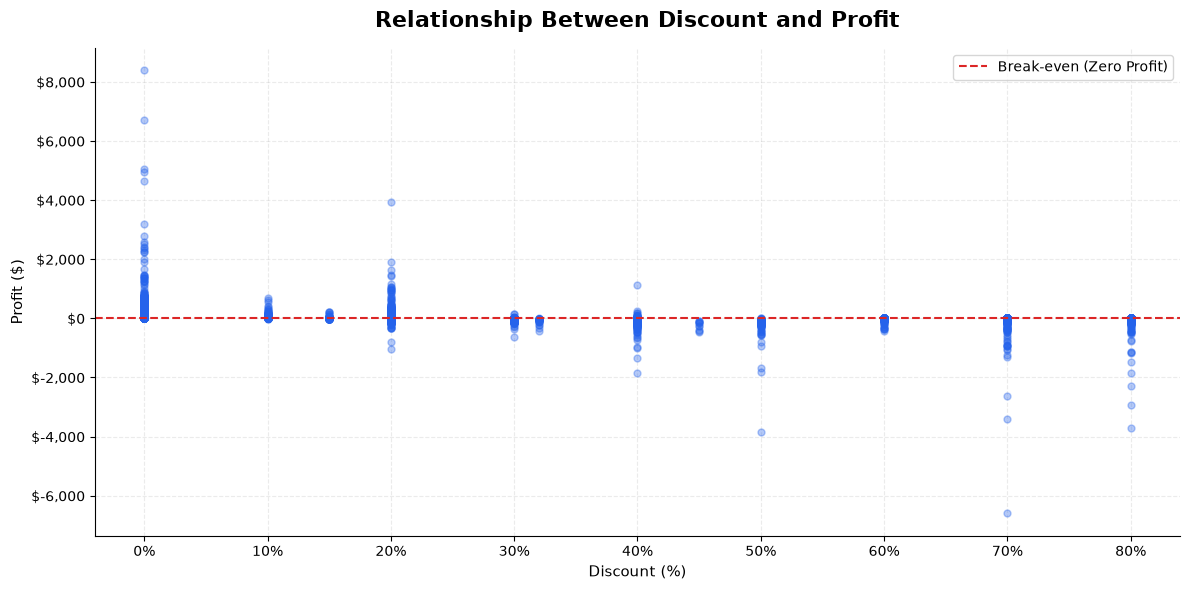

In [39]:

#Discount vs Profit Analysis

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

# Create chart
fig, ax = plt.subplots(figsize=(12, 6))

# Plot discount against profit
ax.scatter(
    df_clean["Discount"],
    df_clean["Profit"],
    color="#2563EB",
    alpha=0.35,
    s=25
)

# Add zero-profit reference line
ax.axhline(
    y=0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label="Break-even (Zero Profit)"
)

# Chart title and labels
ax.set_title(
    "Relationship Between Discount and Profit",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Discount (%)", fontsize=11)
ax.set_ylabel("Profit ($)", fontsize=11)

# Format axes
ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Improve appearance
ax.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [40]:

#Discount vs Profit Correlation

# Calculate Pearson correlation
discount_profit_corr = df_clean["Discount"].corr(
    df_clean["Profit"]
)

# Display the result
print(
    f"Correlation between Discount and Profit: "
    f"{discount_profit_corr:.4f}"
)


Correlation between Discount and Profit: -0.2189


In [41]:

#Profitability by Discount Level

discount_analysis = (
    df_clean.groupby("Discount")
    .agg(
        Transactions=("Profit", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Loss_Making_Transactions=("Profit", lambda x: (x < 0).sum())
    )
    .reset_index()
)

# Calculate loss-making transaction percentage
discount_analysis["Loss_Rate"] = (
    discount_analysis["Loss_Making_Transactions"]
    / discount_analysis["Transactions"]
) * 100

# Display results
discount_analysis.round(2)


,Discount,Transactions,Total_Sales,Total_Profit,Average_Profit,Loss_Making_Transactions,Loss_Rate
0,0.00,4925,1105323.79,326718.59,66.34,0,0.00
1,0.10,96,54952.50,9099.97,94.79,4,4.17
2,0.15,52,27558.52,1418.99,27.29,17,32.69
3,0.20,3706,773939.40,91079.95,24.58,510,13.76
4,0.30,230,104474.07,-10513.45,-45.71,211,91.74
5,0.32,27,14493.46,-2391.14,-88.56,27,100.00
6,0.40,207,116497.76,-23086.37,-111.53,181,87.44
7,0.45,11,5484.97,-2493.11,-226.65,11,100.00
8,0.50,66,58918.54,-20506.43,-310.70,66,100.00
9,0.60,149,7105.94,-6164.35,-41.37,149,100.00


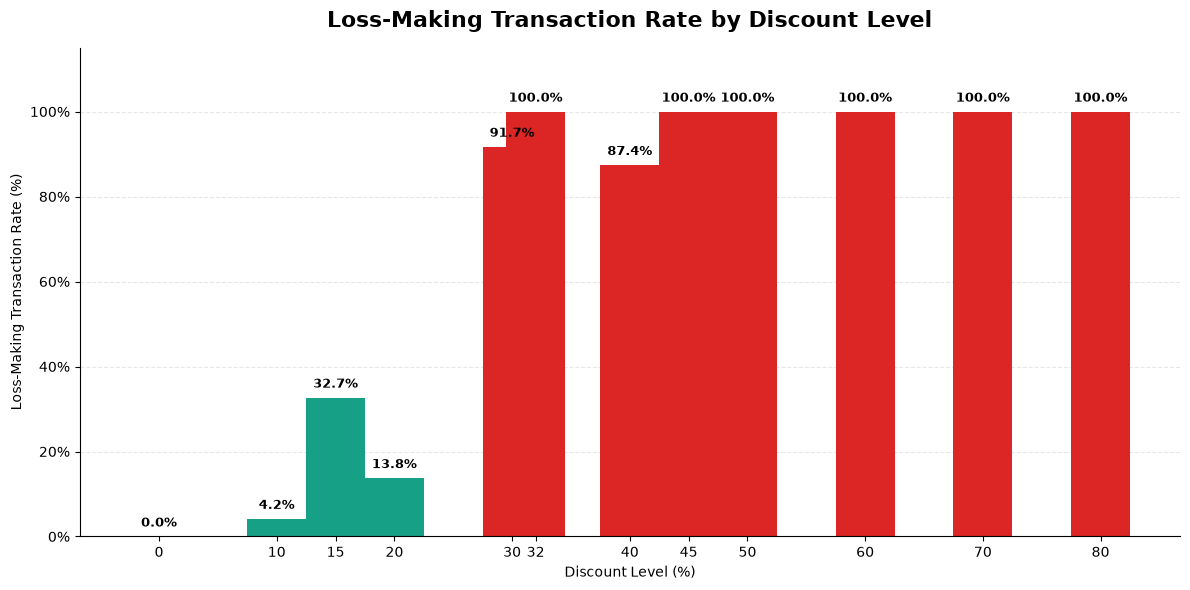

In [42]:

#Loss Rate by Discount Level

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Prepare chart data
discount_chart = discount_analysis.sort_values("Discount")

# Green for lower loss rates, red for higher loss rates
colors = [
    "#DC2626" if rate >= 50 else "#16A085"
    for rate in discount_chart["Loss_Rate"]
]

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    discount_chart["Discount"] * 100,
    discount_chart["Loss_Rate"],
    width=5,
    color=colors
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.set_title(
    "Loss-Making Transaction Rate by Discount Level",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Discount Level (%)")
ax.set_ylabel("Loss-Making Transaction Rate (%)")

ax.set_xticks(discount_chart["Discount"] * 100)
ax.set_ylim(0, 115)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [43]:

#Discount Impact by Product Category

# Group sales by category and discount level
category_discount_analysis = (
    df_clean.groupby(["Category", "Discount"])
    .agg(
        Transactions=("Profit", "size"),
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Loss_Making_Transactions=(
            "Profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

# Calculate profit margin
category_discount_analysis["Profit_Margin"] = (
    category_discount_analysis["Total_Profit"]
    / category_discount_analysis["Total_Revenue"]
) * 100

# Calculate loss rate
category_discount_analysis["Loss_Rate"] = (
    category_discount_analysis["Loss_Making_Transactions"]
    / category_discount_analysis["Transactions"]
) * 100

# Sort by category and discount
category_discount_analysis = (
    category_discount_analysis.sort_values(
        by=["Category", "Discount"]
    )
)

# Display results
category_discount_analysis.round(2)


,Category,Discount,Transactions,Total_Revenue,Total_Profit,Average_Profit,Loss_Making_Transactions,Profit_Margin,Loss_Rate
0,Furniture,0.00,880,260155.06,59476.99,67.59,0,22.86,0.00
1,Furniture,0.10,78,47217.39,7181.80,92.07,4,15.21,5.13
2,Furniture,0.15,52,27558.52,1418.99,27.29,17,5.15,32.69
3,Furniture,0.20,636,223393.35,6608.50,10.39,171,2.96,26.89
4,Furniture,0.30,224,100191.18,-10786.83,-48.16,209,-10.77,93.30
5,Furniture,0.32,27,14493.46,-2391.14,-88.56,27,-16.50,100.00
6,Furniture,0.40,75,45614.41,-16187.40,-215.83,75,-35.49,100.00
7,Furniture,0.45,11,5484.97,-2493.11,-226.65,11,-45.45,100.00
8,Furniture,0.50,54,20983.47,-12871.20,-238.36,54,-61.34,100.00
9,Furniture,0.60,147,7051.98,-6134.07,-41.73,147,-86.98,100.00


In [44]:

#Category Profitability by Discount Group

import numpy as np

# Create discount groups
df_clean["Discount_Group"] = np.select(
    [
        df_clean["Discount"] == 0,
        (df_clean["Discount"] > 0) & (df_clean["Discount"] < 0.30),
        df_clean["Discount"] >= 0.30
    ],
    [
        "No Discount",
        "Low Discount",
        "High Discount"
    ],
    default="Unknown"
)

# Calculate category performance for each discount group
category_discount_summary = (
    df_clean.groupby(["Category", "Discount_Group"])
    .agg(
        Transactions=("Profit", "size"),
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Loss_Making_Transactions=(
            "Profit",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

# Calculate profitability metrics
category_discount_summary["Profit_Margin"] = (
    category_discount_summary["Total_Profit"]
    / category_discount_summary["Total_Revenue"]
) * 100

category_discount_summary["Loss_Rate"] = (
    category_discount_summary["Loss_Making_Transactions"]
    / category_discount_summary["Transactions"]
) * 100

# Display the summary
category_discount_summary.round(2)


,Category,Discount_Group,Transactions,Total_Revenue,Total_Profit,Average_Profit,Loss_Making_Transactions,Profit_Margin,Loss_Rate
0,Furniture,High Discount,555,196423.44,-54956.29,-99.02,540,-27.98,97.30
1,Furniture,Low Discount,766,298169.26,15209.29,19.86,192,5.10,25.07
2,Furniture,No Discount,880,260155.06,59476.99,67.59,0,22.86,0.00
3,Office Supplies,High Discount,689,40240.45,-47306.24,-68.66,689,-117.56,100.00
4,Office Supplies,Low Discount,2241,239242.26,39437.78,17.60,209,16.48,9.33
5,Office Supplies,No Discount,3198,452410.61,133891.90,41.87,0,29.60,0.00
6,Technology,High Discount,171,128096.26,-33758.16,-197.42,141,-26.35,82.46
7,Technology,Low Discount,847,319038.90,46951.84,55.43,130,14.72,15.35
8,Technology,No Discount,847,392758.12,133349.70,157.44,0,33.95,0.00


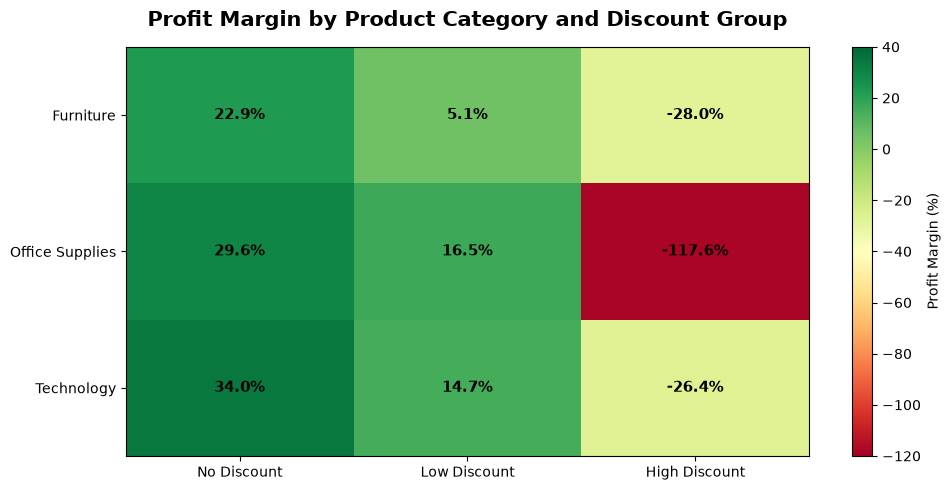

In [45]:

#Discount Impact Heatmap

import matplotlib.pyplot as plt
import numpy as np

# Prepare profit margin data
heatmap_data = category_discount_summary.pivot(
    index="Category",
    columns="Discount_Group",
    values="Profit_Margin"
)

# Arrange columns
heatmap_data = heatmap_data[
    ["No Discount", "Low Discount", "High Discount"]
]

fig, ax = plt.subplots(figsize=(10, 5))

# Create heatmap
im = ax.imshow(
    heatmap_data,
    cmap="RdYlGn",
    aspect="auto",
    vmin=-120,
    vmax=40
)

# Set labels
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_yticks(np.arange(len(heatmap_data.index)))

ax.set_xticklabels(heatmap_data.columns)
ax.set_yticklabels(heatmap_data.index)

# Add values inside cells
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="black"
        )

ax.set_title(
    "Profit Margin by Product Category and Discount Group",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Add colour scale
colorbar = fig.colorbar(im, ax=ax)
colorbar.set_label("Profit Margin (%)")

plt.tight_layout()
plt.show()


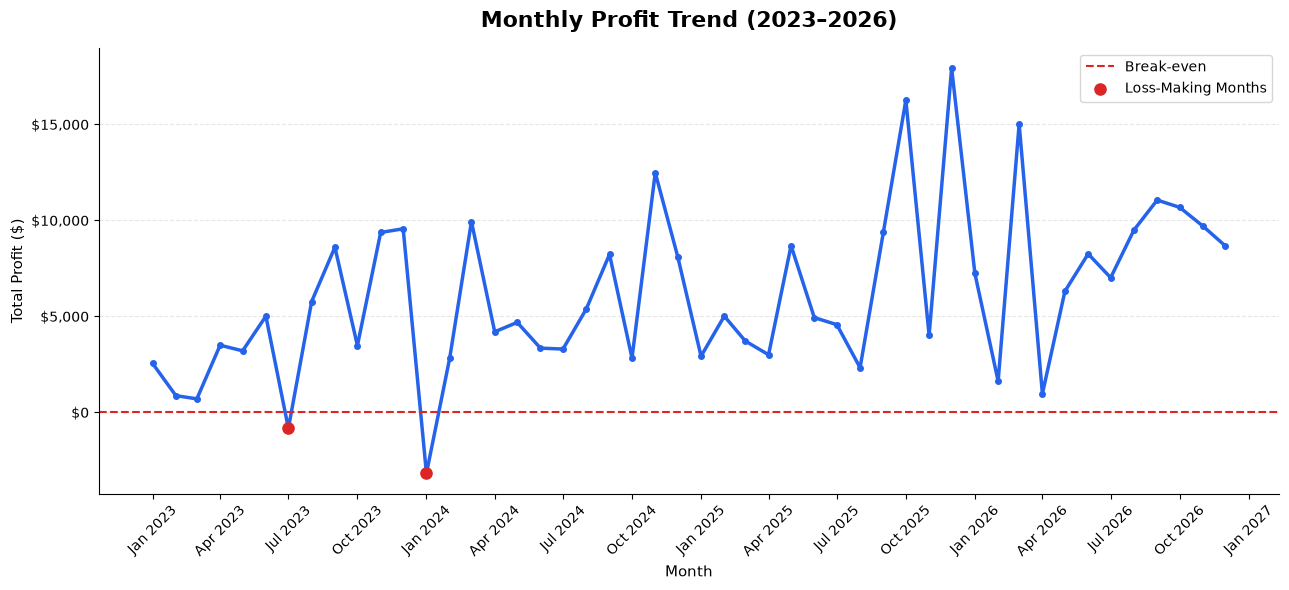

In [46]:

#Monthly Profit Trend

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Prepare monthly profit data
monthly_profit_chart = monthly_performance.copy()

# Convert Year_Month to datetime for plotting
monthly_profit_chart["Year_Month"] = (
    monthly_profit_chart["Year_Month"].dt.to_timestamp()
)

# Sort chronologically
monthly_profit_chart = monthly_profit_chart.sort_values(
    by="Year_Month"
)

# Create chart
fig, ax = plt.subplots(figsize=(13, 6))

# Plot monthly profit
ax.plot(
    monthly_profit_chart["Year_Month"],
    monthly_profit_chart["Total_Profit"],
    color="#2563EB",
    linewidth=2.5,
    marker="o",
    markersize=4
)

# Add zero-profit reference line
ax.axhline(
    y=0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label="Break-even"
)

# Highlight loss-making months
loss_months = monthly_profit_chart[
    monthly_profit_chart["Total_Profit"] < 0
]

ax.scatter(
    loss_months["Year_Month"],
    loss_months["Total_Profit"],
    color="#DC2626",
    s=65,
    zorder=5,
    label="Loss-Making Months"
)

# Format date axis
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)

# Format currency axis
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Titles and labels
ax.set_title(
    "Monthly Profit Trend (2023–2026)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Total Profit ($)", fontsize=11)

# Improve appearance
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [47]:

#Annual Revenue and Profit Analysis

# Create a Year column from Order Date
df_clean["Year"] = df_clean["Order Date"].dt.year

# Group sales data by year
annual_performance = (
    df_clean.groupby("Year")
    .agg(
        Total_Revenue=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate annual profit margin
annual_performance["Profit_Margin"] = (
    annual_performance["Total_Profit"]
    / annual_performance["Total_Revenue"]
) * 100

# Sort by year
annual_performance = annual_performance.sort_values(
    by="Year"
)

# Display annual performance
annual_performance.round(2)


,Year,Total_Revenue,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
0,2023,494040.21,51684.30,995,7813,10.46
1,2024,472993.03,62020.97,1053,8086,13.11
2,2025,613933.58,82665.20,1340,10018,13.46
3,2026,745567.53,95926.35,1723,12737,12.87


In [48]:

#Year-over-Year Growth Analysis

# Create a copy of annual performance
annual_growth = annual_performance.copy()

# Ensure years are in chronological order
annual_growth = annual_growth.sort_values("Year")

# Calculate year-over-year revenue growth
annual_growth["Revenue_Growth_%"] = (
    annual_growth["Total_Revenue"].pct_change() * 100
)

# Calculate year-over-year profit growth
annual_growth["Profit_Growth_%"] = (
    annual_growth["Total_Profit"].pct_change() * 100
)

# Display the results
annual_growth[
    [
        "Year",
        "Total_Revenue",
        "Revenue_Growth_%",
        "Total_Profit",
        "Profit_Growth_%",
        "Profit_Margin"
    ]
].round(2)


,Year,Total_Revenue,Revenue_Growth_%,Total_Profit,Profit_Growth_%,Profit_Margin
0,2023,494040.21,NaN,51684.30,NaN,10.46
1,2024,472993.03,-4.26,62020.97,20.00,13.11
2,2025,613933.58,29.80,82665.20,33.29,13.46
3,2026,745567.53,21.44,95926.35,16.04,12.87


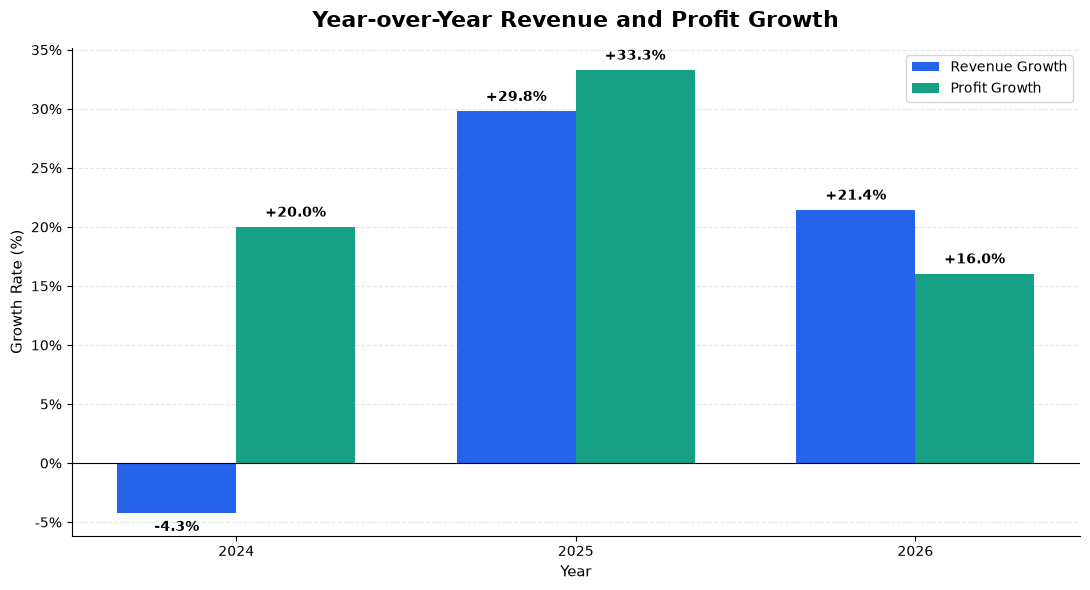

In [49]:

#Year-over-Year Growth Chart

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# Exclude baseline year (2023)
growth_chart = annual_growth.dropna(
    subset=["Revenue_Growth_%", "Profit_Growth_%"]
).copy()

# Set bar positions
x = np.arange(len(growth_chart["Year"]))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

# Revenue growth bars
revenue_bars = ax.bar(
    x - width / 2,
    growth_chart["Revenue_Growth_%"],
    width,
    label="Revenue Growth",
    color="#2563EB"
)

# Profit growth bars
profit_bars = ax.bar(
    x + width / 2,
    growth_chart["Profit_Growth_%"],
    width,
    label="Profit Growth",
    color="#16A085"
)

# Add percentage labels
for bars in [revenue_bars, profit_bars]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:+.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5 if height >= 0 else -5),
            textcoords="offset points",
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=10,
            fontweight="bold"
        )

# Add zero-growth reference line
ax.axhline(0, color="black", linewidth=0.8)

# Chart title and labels
ax.set_title(
    "Year-over-Year Revenue and Profit Growth",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Growth Rate (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(growth_chart["Year"].astype(str))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"{value:.0f}%")
)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [50]:

#Export Cleaned Dataset for SQL

from pathlib import Path

# Create the data folder if it doesn't exist
output_folder = Path("../data")
output_folder.mkdir(parents=True, exist_ok=True)

# Define the output file
output_file = output_folder / "sales_cleaned.csv"

# Export cleaned data
df_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8"
)

# Confirm export
print("Cleaned dataset exported successfully!")
print(f"File location: {output_file.resolve()}")
print(f"Rows exported: {len(df_clean):,}")
print(f"Columns exported: {len(df_clean.columns)}")


Cleaned dataset exported successfully!
File location: C:\Users\HighveldVR2\OneDrive - CHIETA\Desktop\CEE_NYAMBANE_PD\sales-performance-analytics\data\sales_cleaned.csv
Rows exported: 10,194
Columns exported: 24


In [51]:

#Final CSV Verification

import pandas as pd
from pathlib import Path

# Locate the exported CSV file
csv_file = Path("../data/sales_cleaned.csv")

# Load the exported data
df_sql = pd.read_csv(csv_file)

# Verify dataset
print("FINAL PYTHON DATA VERIFICATION")
print("-" * 40)

print(f"File exists: {csv_file.exists()}")
print(f"Total rows: {len(df_sql):,}")
print(f"Total columns: {len(df_sql.columns)}")
print(f"Missing values: {df_sql.isnull().sum().sum()}")
print(f"Duplicate rows: {df_sql.duplicated().sum()}")

# Compare exported dataset with cleaned dataset
print(f"Row counts match: {len(df_sql) == len(df_clean)}")

# Verify financial totals
print(f"Total Revenue: ${df_sql['Sales'].sum():,.2f}")
print(f"Total Profit: ${df_sql['Profit'].sum():,.2f}")

# Final validation
assert len(df_sql) == 10194, "Unexpected row count!"
assert df_sql.isnull().sum().sum() == 0, "Missing values found!"
assert df_sql.duplicated().sum() == 0, "Duplicate rows found!"
assert len(df_sql) == len(df_clean), "Row counts do not match!"

print("-" * 40)
print("SUCCESS: Dataset is ready for SQL!")


FINAL PYTHON DATA VERIFICATION
----------------------------------------
File exists: True
Total rows: 10,194
Total columns: 24
Missing values: 0
Duplicate rows: 0
Row counts match: True
Total Revenue: $2,326,534.35
Total Profit: $292,296.81
----------------------------------------
SUCCESS: Dataset is ready for SQL!


In [52]:

import pandas as pd
from pathlib import Path

# Load the cleaned CSV
csv_file = Path("../data/sales_cleaned.csv")
df_sql = pd.read_csv(csv_file)

# Display column names in order
print("CSV COLUMN VERIFICATION")
print("-" * 45)

for position, column in enumerate(df_sql.columns, start=1):
    print(f"{position:2}. {column}")

print("-" * 45)
print(f"Total columns: {len(df_sql.columns)}")
print(f"Total records: {len(df_sql):,}")


CSV COLUMN VERIFICATION
---------------------------------------------
 1. Row ID
 2. Order ID
 3. Order Date
 4. Ship Date
 5. Ship Mode
 6. Customer ID
 7. Customer Name
 8. Segment
 9. Country/Region
10. City
11. State/Province
12. Postal Code
13. Region
14. Product ID
15. Category
16. Sub-Category
17. Product Name
18. Sales
19. Quantity
20. Discount
21. Profit
22. Year_Month
23. Discount_Group
24. Year
---------------------------------------------
Total columns: 24
Total records: 10,194


In [53]:

import pandas as pd
from pathlib import Path

# Load the cleaned sales dataset
df_import = pd.read_csv("../data/sales_cleaned.csv")

# Convert dates to SQL-friendly format
df_import["Order Date"] = pd.to_datetime(
    df_import["Order Date"]
).dt.strftime("%Y-%m-%d")

df_import["Ship Date"] = pd.to_datetime(
    df_import["Ship Date"]
).dt.strftime("%Y-%m-%d")

# Save a separate SQL import file
output_file = Path("../data/sales_sql_import.csv")

df_import.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("SQL IMPORT FILE CREATED")
print("-" * 40)
print(f"File: {output_file.resolve()}")
print(f"Total records: {len(df_import):,}")
print(f"Total columns: {len(df_import.columns)}")

print("\nSample dates:")
print(df_import[["Order Date", "Ship Date"]].head())


SQL IMPORT FILE CREATED
----------------------------------------
File: C:\Users\HighveldVR2\OneDrive - CHIETA\Desktop\CEE_NYAMBANE_PD\sales-performance-analytics\data\sales_sql_import.csv
Total records: 10,194
Total columns: 24

Sample dates:
   Order Date   Ship Date
0  2023-01-03  2023-01-07
1  2023-01-04  2023-01-08
2  2023-01-04  2023-01-08
3  2023-01-04  2023-01-08
4  2023-01-05  2023-01-12


In [54]:

from pathlib import Path

csv_path = Path("../data/sales_sql_import.csv").resolve()

print("SQL IMPORT FILE PATH")
print("-" * 50)
print(csv_path)
print(f"\nFile exists: {csv_path.exists()}")
print(f"File size: {csv_path.stat().st_size:,} bytes")


SQL IMPORT FILE PATH
--------------------------------------------------
C:\Users\HighveldVR2\OneDrive - CHIETA\Desktop\CEE_NYAMBANE_PD\sales-performance-analytics\data\sales_sql_import.csv

File exists: True
File size: 2,744,401 bytes


In [56]:

import pandas as pd
from pathlib import Path

# Load the SQL-ready CSV
df_sql = pd.read_csv("../data/sales_sql_import.csv")

# Round numeric columns to match SQL Server
df_sql["Sales"] = df_sql["Sales"].round(4)
df_sql["Profit"] = df_sql["Profit"].round(4)
df_sql["Discount"] = df_sql["Discount"].round(2)

# Save the final SQL import file
output_path = Path("../data/sales_sql_final.csv")

df_sql.to_csv(
    output_path,
    index=False,
    encoding="utf-8",
    float_format="%.4f"
)

print("Final SQL CSV created successfully!")
print(f"Records: {len(df_sql):,}")
print(f"Columns: {len(df_sql.columns)}")
print(f"File: {output_path.resolve()}")


Final SQL CSV created successfully!
Records: 10,194
Columns: 24
File: C:\Users\HighveldVR2\OneDrive - CHIETA\Desktop\CEE_NYAMBANE_PD\sales-performance-analytics\data\sales_sql_final.csv


In [57]:

from pathlib import Path
import shutil

# Original CSV file
source = Path("../data/sales_sql_final.csv").resolve()

# New SQL Server import location
destination_folder = Path("C:/SQLData")
destination_folder.mkdir(parents=True, exist_ok=True)

destination = destination_folder / "sales_sql_final.csv"

# Copy the CSV
shutil.copy2(source, destination)

# Verify the copy
print("File copied successfully!")
print("New location:", destination)
print("File exists:", destination.exists())
print("File size:", destination.stat().st_size, "bytes")


File copied successfully!
New location: C:\SQLData\sales_sql_final.csv
File exists: True
File size: 2675892 bytes
